# MENOS vs Qiskit Aer vs PennyLane Lightning

This notebook runs the same circuits through three simulators and compares the
answers and the wall-clock time:

| Column | Simulator | How it is driven |
|---|---|---|
| `menos` | MENOS (`menos.run`, planner chooses the engine) | native `menos.Circuit` |
| `aer` | Qiskit Aer `AerSimulator(method="automatic")` | `qiskit.QuantumCircuit` |
| `lightning` | PennyLane `lightning.qubit` (`default.mixed` for the noisy case) | `qml.qnode` |

Circuit families: GHZ, QFT, random dense layers, QAOA MaxCut, a hardware-efficient
ansatz under a Heisenberg Hamiltonian, Trotterised transverse-field Ising, random
Clifford circuits, and a depolarising-noise circuit. Each family is tried at a few
qubit counts and with three kinds of output: the full statevector, sampled counts,
or an expectation value.

Every circuit is written once as a framework-neutral gate list and lowered to each
framework, so all three simulate exactly the same gates. All bit conventions are
normalised to Qiskit's (qubit 0 is the rightmost character of a bitstring and the
lowest bit of a statevector index).

Timing: one warm-up run, then the best of `REPEATS` timed runs, wall-clock, for a
single circuit. All three simulators use every hardware thread they can. The MENOS
figure includes planning; its planning time is reported separately as well.

Requirements: `pip install "menos[test]"` installs qiskit, qiskit-aer and
pennylane; `pennylane-lightning` ships with pennylane. Timings below are from one
machine and will differ on yours.

In [2]:
!pip install qiskit_aer

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.9 MB 694.9 kB/s eta 0:00:14
   -- ------------------------------------- 0.5/9.9 MB 694.9 kB/s eta 0:00:14
   --- ------------------------------------ 0.8/9.9 MB 794.9 kB/s eta 0:00:12
   ---- ----------------------------------- 1.0/9.9 MB 886.1 kB/s eta 0:00:10
   ---- ----------------------------------- 1.0/9.9 MB 886.1 kB/s eta 0:00:10
   ----- ---------------------------------- 1.3/9.9 MB 779.9 kB/s eta 0:00:11
   ------ --------------------------------- 1.6/9.9 MB 836.6 kB/s eta 0:00:10
   ------- -------------------------------- 1.8/9.9 MB 899.4 kB/s eta 0:00:09
   -------- ------------------------------- 2.1/9.9 MB 926.1 kB/s eta 0:00:09
   --------- 


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\janak\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import math
import os
import platform
import time

import numpy as np
import pandas as pd

import menos
import qiskit
import qiskit_aer
import pennylane as qml
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator

SEED = 12345
REPEATS = 3

print(f"menos {menos.__version__} | qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | pennylane {qml.__version__}")
print(f"{platform.system()} {platform.machine()}, {os.cpu_count()} hardware threads, Python {platform.python_version()}")

menos 1.2.0 | qiskit 2.5.2 | qiskit-aer 0.18.2 | pennylane 0.44.1
Windows AMD64, 22 hardware threads, Python 3.13.14


## 0. The same Bell state three ways

Before the benchmark, the three APIs side by side on one circuit. MENOS plugs into
Qiskit as a `BackendV2` and an `EstimatorV2`, and into PennyLane as the
`menos.qubit` device, so a Qiskit or PennyLane user never touches the native API.

In [4]:
from menos.qiskit import MENOSBackend, MENOSEstimator

bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
zz_xx = SparsePauliOp.from_list([("ZZ", 1.0), ("XX", 0.5)])
bell_measured = bell.measure_all(inplace=False)
bell_ev = bell.copy()
bell_ev.save_expectation_value(zz_xx, [0, 1])

# Qiskit style: MENOS as a BackendV2 / EstimatorV2, Aer the same way.
menos_counts = MENOSBackend().run(bell_measured, shots=2000, seed_simulator=SEED).result().get_counts()
menos_ev = float(MENOSEstimator().run([(bell, zz_xx)]).result()[0].data.evs)
aer_counts = AerSimulator(seed_simulator=SEED).run(bell_measured, shots=2000).result().get_counts()
aer_ev = AerSimulator().run(bell_ev).result().data(0)["expectation_value"]

# PennyLane style: MENOS as the menos.qubit device, lightning.qubit the same way.
def pl_bell_counts(device):
    @qml.set_shots(2000)
    @qml.qnode(device)
    def f():
        qml.Hadamard(0)
        qml.CNOT([0, 1])
        return qml.counts(wires=[0, 1])
    return {k[::-1]: int(v) for k, v in f().items()}  # wire 0 leftmost in PennyLane -> rightmost in Qiskit

def pl_bell_ev(device):
    @qml.qnode(device)
    def f():
        qml.Hadamard(0)
        qml.CNOT([0, 1])
        return qml.expval(qml.Z(0) @ qml.Z(1) + 0.5 * (qml.X(0) @ qml.X(1)))
    return float(f())

menos_dev = qml.device("menos.qubit", wires=2, seed=SEED)
lightning_dev = qml.device("lightning.qubit", wires=2, seed=SEED)

print("counts      menos:", dict(menos_counts), " aer:", dict(aer_counts))
print("            menos.qubit:", pl_bell_counts(menos_dev), " lightning:", pl_bell_counts(lightning_dev))
print(f"<ZZ+0.5XX>  menos {menos_ev:.12f}  aer {aer_ev:.12f}  menos.qubit {pl_bell_ev(menos_dev):.12f}  lightning {pl_bell_ev(lightning_dev):.12f}")

DeviceError: Device menos.qubit does not exist. Make sure the required plugin is installed.

## 1. Circuit families

A case is a qubit count, a gate list `(name, qubits, params)`, a task
(`statevector`, `counts` or `expectation`) and, for expectations, a Pauli
observable as `(coefficient, {qubit: "X"|"Y"|"Z"})` terms.

In [ ]:
class Case:
    def __init__(self, name, n, gates, task, shots=0, observable=None, noisy=False):
        self.name, self.n, self.gates, self.task = name, n, gates, task
        self.shots, self.observable, self.noisy = shots, observable, noisy

    def __repr__(self):
        return f"Case({self.name}: n={self.n}, {len(self.gates)} gates, {self.task})"


def ghz(n, shots=10_000):
    gates = [("h", [0], [])] + [("cx", [q, q + 1], []) for q in range(n - 1)]
    return Case(f"ghz_counts_n{n}", n, gates, "counts", shots=shots)


def qft(n):
    gates = []
    for i in range(n):
        gates.append(("h", [i], []))
        for j in range(i + 1, n):
            gates.append(("cp", [j, i], [math.pi / 2 ** (j - i)]))
    for i in range(n // 2):
        gates.append(("swap", [i, n - 1 - i], []))
    return Case(f"qft_sv_n{n}", n, gates, "statevector")


def random_dense(n, depth, seed=0, task="statevector", shots=10_000):
    rng = np.random.default_rng(seed)
    gates = []
    for _ in range(depth):
        for q in range(n):
            gates.append(("u", [q], list(rng.uniform(0, 2 * math.pi, 3))))
        perm = rng.permutation(n)
        for a, b in zip(perm[::2], perm[1::2]):
            gates.append(("cx", [int(a), int(b)], []))
    return Case(f"random_{'sv' if task == 'statevector' else task}_n{n}_d{depth}", n, gates, task, shots=shots)


def qaoa_maxcut(n, p=2, seed=0):
    rng = np.random.default_rng(seed)
    edges = {(q, (q + 1) % n) for q in range(n)}
    while len(edges) < 2 * n:
        a, b = sorted(rng.choice(n, 2, replace=False))
        edges.add((int(a), int(b)))
    edges = sorted(edges)
    gates = [("h", [q], []) for q in range(n)]
    for layer in range(p):
        gamma, beta = rng.uniform(0, math.pi, 2)
        gates += [("rzz", [a, b], [2 * gamma]) for a, b in edges]
        gates += [("rx", [q], [2 * beta]) for q in range(n)]
    observable = [(0.5 * len(edges), {})] + [(-0.5, {a: "Z", b: "Z"}) for a, b in edges]  # MaxCut cost
    return Case(f"qaoa_ev_n{n}_p{p}", n, gates, "expectation", observable=observable)


def hea_heisenberg(n, layers=4, seed=0):
    rng = np.random.default_rng(seed)
    gates = []
    for _ in range(layers):
        gates += [("ry", [q], [float(rng.uniform(0, 2 * math.pi))]) for q in range(n)]
        gates += [("cx", [q, q + 1], []) for q in range(0, n - 1, 2)]
        gates += [("cx", [q, q + 1], []) for q in range(1, n - 1, 2)]
    observable = [(1.0, {q: P, q + 1: P}) for q in range(n - 1) for P in "XYZ"]
    return Case(f"hea_heisenberg_ev_n{n}", n, gates, "expectation", observable=observable)


def trotter_tfim(n, steps=10, dt=0.1, h=1.0):
    gates = [("h", [q], []) for q in range(n)]
    for _ in range(steps):
        gates += [("rzz", [q, q + 1], [-2 * dt]) for q in range(n - 1)]
        gates += [("rx", [q], [-2 * h * dt]) for q in range(n)]
    observable = [(-1.0, {q: "Z", q + 1: "Z"}) for q in range(n - 1)] + [(-h, {q: "X"}) for q in range(n)]
    return Case(f"trotter_tfim_ev_n{n}", n, gates, "expectation", observable=observable)


def random_clifford(n, depth, seed=0, shots=10_000):
    rng = np.random.default_rng(seed)
    gates = []
    for _ in range(depth):
        for q in range(n):
            gates.append((rng.choice(["h", "s", "h"]), [q], []))
        perm = rng.permutation(n)
        for a, b in zip(perm[::2], perm[1::2]):
            gates.append(("cx", [int(a), int(b)], []))
    return Case(f"clifford_counts_n{n}_d{depth}", n, gates, "counts", shots=shots)


def noisy_random(n, depth, p1=0.001, p2=0.01, seed=0, shots=10_000):
    base = random_dense(n, depth, seed=seed, task="counts", shots=shots)
    gates = []
    for name, qubits, params in base.gates:
        gates.append((name, qubits, params))
        gates.append(("dep1", qubits, [p1]) if len(qubits) == 1 else ("dep2", qubits, [p2]))
    return Case(f"noisy_counts_n{n}_d{depth}", n, gates, "counts", shots=shots, noisy=True)


CASES = [
    ghz(4), ghz(20),
    qft(12), qft(16), qft(20),
    random_dense(12, 10), random_dense(16, 10), random_dense(20, 10),
    random_dense(20, 10, task="counts"),
    qaoa_maxcut(12), qaoa_maxcut(16), qaoa_maxcut(20),
    hea_heisenberg(12), hea_heisenberg(16), hea_heisenberg(20),
    trotter_tfim(12), trotter_tfim(16), trotter_tfim(20),
    random_clifford(20, 10), random_clifford(40, 10),
    noisy_random(6, 6), noisy_random(8, 6),
]
pd.DataFrame([{"case": c.name, "qubits": c.n, "gates": len(c.gates), "task": c.task, "shots": c.shots or ""} for c in CASES])

,case,qubits,gates,task,shots
0,ghz_counts_n4,4,4,counts,10000
1,ghz_counts_n20,20,20,counts,10000
2,qft_sv_n12,12,84,statevector,
3,qft_sv_n16,16,144,statevector,
4,qft_sv_n20,20,220,statevector,
5,random_sv_n12_d10,12,180,statevector,10000
6,random_sv_n16_d10,16,240,statevector,10000
7,random_sv_n20_d10,20,300,statevector,10000
8,random_counts_n20_d10,20,300,counts,10000
9,qaoa_ev_n12_p2,12,84,expectation,


## 2. Lowering to each framework

The gate list becomes a `menos.Circuit`, a `qiskit.QuantumCircuit` and a PennyLane
QNode. Depolarising noise is a Kraus channel after each gate in all three: MENOS
`append_channel`, an Aer `NoiseModel` with the same channel on every gate, and
PennyLane's `DepolarizingChannel` / `QubitChannel`.

In [ ]:
PAULI = {
    "I": np.eye(2, dtype=complex),
    "X": np.array([[0, 1], [1, 0]], dtype=complex),
    "Y": np.array([[0, -1j], [1j, 0]], dtype=complex),
    "Z": np.array([[1, 0], [0, -1]], dtype=complex),
}


def depolarizing_kraus(p, k):
    # (1-p) rho + p/(4^k-1) sum_{P != I} P rho P
    ops = [PAULI[a] for a in "IXYZ"] if k == 1 else [np.kron(PAULI[a], PAULI[b]) for a in "IXYZ" for b in "IXYZ"]
    return [math.sqrt(1 - p) * ops[0]] + [math.sqrt(p / (len(ops) - 1)) * op for op in ops[1:]]


# ---- MENOS (native API) --------------------------------------------------
O = menos.Opcode
MENOS_OPCODES = {"h": O.H, "x": O.X, "s": O.S, "sdg": O.Sdg, "t": O.T, "rx": O.RX, "ry": O.RY, "rz": O.RZ,
                 "u": O.U, "cx": O.CX, "cz": O.CZ, "swap": O.SWAP, "cp": O.CP, "rzz": O.RZZ}


def menos_observable(terms, n):
    from menos._core import Observable, PauliString
    words = (n + 63) // 64
    obs = Observable()
    out = []
    for coeff, paulis in terms:
        x_words, z_words = [0] * words, [0] * words
        for q, P in paulis.items():
            if P in "XY":
                x_words[q // 64] |= 1 << (q % 64)
            if P in "ZY":
                z_words[q // 64] |= 1 << (q % 64)
        ps = PauliString()
        ps.num_qubits, ps.x_words, ps.z_words = n, x_words, z_words
        out.append((ps, complex(coeff)))
    obs.terms = out
    return obs


def menos_job(case):
    c = menos.Circuit(case.n, case.n if case.task == "counts" else 0)
    for name, qubits, params in case.gates:
        if name in ("dep1", "dep2"):
            c.append_channel(list(qubits), [list(k.ravel()) for k in depolarizing_kraus(params[0], len(qubits))])
        else:
            c.append(MENOS_OPCODES[name], list(qubits), list(params))
    if case.task == "counts":
        for q in range(case.n):
            c.append_measure(q, q)
    o = menos.RunOptions()
    o.seed = SEED
    if case.task == "statevector":
        o.want_statevector = True
    elif case.task == "counts":
        o.shots = case.shots
    else:
        o.expectation = menos_observable(case.observable, case.n)
    return c, o


def run_menos(case):
    circuit, options = menos_job(case)
    def go():
        return menos.run(circuit, options)
    return go


def menos_output(case, r):
    if case.task == "statevector":
        return np.asarray(r.statevector)
    if case.task == "counts":
        return {format(int(k, 16), f"0{case.n}b"): int(v) for k, v in r.counts.items()}
    return float(np.real(r.expectation_value))


def menos_plan(r):
    for line in r.explain().splitlines():
        if line.startswith("strategy"):
            return line.split(None, 1)[1].strip()
    return "?"


# ---- Qiskit Aer ------------------------------------------------------------
def qiskit_circuit(case):
    qc = QuantumCircuit(case.n, case.n if case.task == "counts" else 0)
    for name, qubits, params in case.gates:
        if name in ("dep1", "dep2"):
            continue  # noise comes from the Aer NoiseModel instead
        getattr(qc, name)(*params, *qubits)
    if case.task == "counts":
        qc.measure(range(case.n), range(case.n))
    elif case.task == "statevector":
        qc.save_statevector()
    else:
        qc.save_expectation_value(qiskit_observable(case.observable, case.n), list(range(case.n)))
    return qc


def qiskit_observable(terms, n):
    labels = []
    for coeff, paulis in terms:
        label = ["I"] * n
        for q, P in paulis.items():
            label[n - 1 - q] = P  # Qiskit labels: qubit 0 is the rightmost character
        labels.append(("".join(label), coeff))
    return SparsePauliOp.from_list(labels)


def aer_noise_model(case):
    from qiskit_aer.noise import NoiseModel, depolarizing_error
    p1 = next(p[0] for name, _, p in case.gates if name == "dep1")
    p2 = next(p[0] for name, _, p in case.gates if name == "dep2")
    nm = NoiseModel()
    # Aer's depolarizing_error(lam, k) is (1-lam) rho + lam I/2^k; our Kraus form is lam = p * 4^k / (4^k - 1).
    nm.add_all_qubit_quantum_error(depolarizing_error(p1 * 4 / 3, 1), ["u", "h", "rx", "ry", "rz", "s", "t", "x"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p2 * 16 / 15, 2), ["cx", "cz", "rzz", "cp", "swap"])
    return nm


def run_aer(case):
    qc = qiskit_circuit(case)
    if case.noisy:
        sim = AerSimulator(method="density_matrix", seed_simulator=SEED, noise_model=aer_noise_model(case))
    else:
        sim = AerSimulator(method="automatic", seed_simulator=SEED)
    shots = case.shots if case.task == "counts" else 1
    def go():
        return sim.run(qc, shots=shots).result()
    return go


def aer_output(case, result):
    if case.task == "statevector":
        return np.asarray(result.get_statevector())
    if case.task == "counts":
        return {k: int(v) for k, v in result.get_counts().items()}
    return float(result.data(0)["expectation_value"])


# ---- PennyLane -------------------------------------------------------------
def pl_apply(name, qubits, params):
    if name == "h": qml.Hadamard(qubits[0])
    elif name == "x": qml.PauliX(qubits[0])
    elif name == "s": qml.S(qubits[0])
    elif name == "sdg": qml.adjoint(qml.S)(qubits[0])
    elif name == "t": qml.T(qubits[0])
    elif name == "rx": qml.RX(params[0], qubits[0])
    elif name == "ry": qml.RY(params[0], qubits[0])
    elif name == "rz": qml.RZ(params[0], qubits[0])
    elif name == "u": qml.U3(*params, wires=qubits[0])
    elif name == "cx": qml.CNOT(qubits)
    elif name == "cz": qml.CZ(qubits)
    elif name == "swap": qml.SWAP(qubits)
    elif name == "cp": qml.ControlledPhaseShift(params[0], wires=qubits)
    elif name == "rzz": qml.IsingZZ(params[0], wires=qubits)
    elif name == "dep1": qml.DepolarizingChannel(params[0], wires=qubits[0])
    elif name == "dep2": qml.QubitChannel(depolarizing_kraus(params[0], 2), wires=qubits)
    else: raise ValueError(name)


PL_PAULI = {"X": qml.X, "Y": qml.Y, "Z": qml.Z}


def pl_observable(terms, n):
    coeffs, ops = [], []
    for coeff, paulis in terms:
        op = qml.Identity(0)
        for q, P in paulis.items():
            op = op @ PL_PAULI[P](q)
        coeffs.append(coeff)
        ops.append(op)
    return qml.Hamiltonian(coeffs, ops)


def run_pennylane(case):
    device = qml.device("default.mixed" if case.noisy else "lightning.qubit", wires=case.n, seed=SEED)
    gates, n = case.gates, case.n
    if case.task == "counts":
        @qml.set_shots(case.shots)
        @qml.qnode(device)
        def f():
            for g in gates: pl_apply(*g)
            return qml.counts(wires=range(n))
    elif case.task == "statevector":
        @qml.qnode(device)
        def f():
            for g in gates: pl_apply(*g)
            return qml.state()
    else:
        H = pl_observable(case.observable, n)
        @qml.qnode(device)
        def f():
            for g in gates: pl_apply(*g)
            return qml.expval(H)
    return f


def pennylane_output(case, out):
    if case.task == "statevector":
        # PennyLane's state is big-endian (wire 0 is the most significant bit); flip to Qiskit's order.
        return np.asarray(out).reshape([2] * case.n).transpose(range(case.n - 1, -1, -1)).ravel()
    if case.task == "counts":
        return {k[::-1]: int(v) for k, v in out.items()}
    return float(out)


RUNNERS = {"menos": (run_menos, menos_output), "aer": (run_aer, aer_output), "lightning": (run_pennylane, pennylane_output)}

## 3. Agreement metrics

* statevector: fidelity $|\langle\psi_a|\psi_b\rangle|^2$ against MENOS (1 means identical up to a phase);
* counts: the largest difference in any single-qubit marginal $P(q_i = 1)$ against MENOS. Two
  independent samples of `shots` draws differ by about $2/\sqrt{\text{shots}}$ even when
  the underlying distributions are identical, so that is the noise floor;
* expectation: the absolute difference against MENOS.

In [ ]:
def marginals(counts, n):
    shots = sum(counts.values())
    p = np.zeros(n)
    for key, c in counts.items():
        for i in range(n):
            if key[n - 1 - i] == "1":
                p[i] += c
    return p / shots


def agreement(case, reference, other):
    if case.task == "statevector":
        return abs(np.vdot(reference, other)) ** 2
    if case.task == "counts":
        return float(np.max(np.abs(marginals(reference, case.n) - marginals(other, case.n))))
    return abs(reference - other)


def timed(go):
    go()  # warm-up
    best, out = math.inf, None
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        out = go()
        best = min(best, time.perf_counter() - t0)
    return best, out


def skip(sim, case):
    if sim == "lightning" and case.n > 26:
        return "statevector would need %d GiB" % (16 * 2 ** case.n // 2 ** 30)
    return None

## 4. Run everything

`REPEATS` timed runs per simulator per case, after one warm-up. Change `CASES` or
`REPEATS` above to try other circuits.

In [ ]:
rows = []
for case in CASES:
    row = {"case": case.name, "qubits": case.n, "gates": len(case.gates), "task": case.task}
    reference = None
    for sim, (make, extract) in RUNNERS.items():
        reason = skip(sim, case)
        if reason:
            row[sim] = np.nan
            row[f"{sim}_note"] = reason
            continue
        seconds, raw = timed(make(case))
        out = extract(case, raw)
        row[sim] = seconds
        if sim == "menos":
            reference = out
            row["menos_plan"] = menos_plan(raw)
            row["menos_plan_s"] = raw.plan_seconds
            row["menos_peak_MiB"] = raw.peak_host_bytes / 2 ** 20
            row["exact"] = raw.exact
        else:
            row[f"{sim}_agree"] = agreement(case, reference, out)
    rows.append(row)
    print(f"{case.name:28s} menos {row['menos']:8.4f}s  aer {row.get('aer', np.nan):8.4f}s  lightning {row.get('lightning', np.nan):8.4f}s  plan={row['menos_plan']}")

df = pd.DataFrame(rows).set_index("case")

ghz_counts_n4                menos   0.0020s  aer   0.0814s  lightning   0.0580s  plan=direct_stabilizer (exact)


ghz_counts_n20               menos   0.0772s  aer   0.2492s  lightning   0.3701s  plan=direct_mps (exact)
qft_sv_n12                   menos   0.0013s  aer   0.0139s  lightning   0.0158s  plan=direct_dense (exact)


qft_sv_n16                   menos   0.0568s  aer   0.0338s  lightning   0.0401s  plan=direct_dense (exact)


qft_sv_n20                   menos   0.2719s  aer   0.2410s  lightning   0.5283s  plan=direct_dense (exact)


random_sv_n12_d10            menos   0.0058s  aer   0.0149s  lightning   0.0507s  plan=direct_dense (exact)


random_sv_n16_d10            menos   0.1298s  aer   0.0521s  lightning   0.1924s  plan=direct_dense (exact)


... (9 outputs left out)

clifford_counts_n20_d10      menos   0.0105s  aer   0.2937s  lightning   1.3402s  plan=direct_stabilizer (exact)


clifford_counts_n40_d10      menos   0.0156s  aer   0.7714s  lightning      nans  plan=direct_stabilizer (exact)


noisy_counts_n6_d6           menos   0.0178s  aer   0.0613s  lightning   0.5377s  plan=direct_density_matrix (exact)


noisy_counts_n8_d6           menos   0.2148s  aer   0.0782s  lightning   8.9687s  plan=direct_density_matrix (exact)


## 5. Results

Times are seconds for one circuit (best of `REPEATS`). The `×` columns are the
other simulator's time divided by MENOS's, so a value above 1 means MENOS was
faster. `menos_plan` is the engine the planner chose, and `menos_plan_s` how long
choosing took (included in `menos`).

In [ ]:
table = df[["qubits", "gates", "task", "menos", "aer", "lightning", "menos_plan", "menos_plan_s", "menos_peak_MiB"]].copy()
table["aer/menos"] = df["aer"] / df["menos"]
table["lightning/menos"] = df["lightning"] / df["menos"]
pd.set_option("display.width", 200)
table.round(4)

,qubits,gates,task,menos,aer,lightning,menos_plan,menos_plan_s,menos_peak_MiB,aer/menos,lightning/menos
case,,,,,,,,,,,
ghz_counts_n4,4,4,counts,0.0020,0.0814,0.0580,direct_stabilizer (exact),0.0000,0.0008,40.4507,28.8346
ghz_counts_n20,20,20,counts,0.0772,0.2492,0.3701,direct_mps (exact),0.0001,0.0060,3.2259,4.7910
qft_sv_n12,12,84,statevector,0.0013,0.0139,0.0158,direct_dense (exact),0.0001,0.0625,10.6085,11.9922
qft_sv_n16,16,144,statevector,0.0568,0.0338,0.0401,direct_dense (exact),0.0003,1.0000,0.5959,0.7067
qft_sv_n20,20,220,statevector,0.2719,0.2410,0.5283,direct_dense (exact),0.0003,16.0000,0.8867,1.9432
random_sv_n12_d10,12,180,statevector,0.0058,0.0149,0.0507,direct_dense (exact),0.0002,0.0625,2.5587,8.7324
random_sv_n16_d10,16,240,statevector,0.1298,0.0521,0.1924,direct_dense (exact),0.0004,1.0000,0.4016,1.4829
random_sv_n20_d10,20,300,statevector,0.5710,0.5607,3.2301,direct_dense (exact),0.0004,16.0000,0.9820,5.6574
random_counts_n20_d10,20,300,counts,0.5216,0.6526,3.4811,direct_dense (exact),0.0004,16.8325,1.2512,6.6742


### Do the answers agree?

Fidelity should be 1 to about 1e-12, expectation differences should be at the
1e-12 level, and counts marginals should differ by less than the sampling noise
floor (two samples of the same distribution are not identical).

In [ ]:
agree = df[["task", "aer_agree", "lightning_agree", "exact"]].copy()
agree["noise_floor"] = [2 / math.sqrt(c.shots) if c.task == "counts" else 0.0 for c in CASES]
agree

,task,aer_agree,lightning_agree,exact,noise_floor
case,,,,,
ghz_counts_n4,counts,7.200000e-03,8.000000e-04,True,0.02
ghz_counts_n20,counts,7.200000e-03,2.000000e-03,True,0.02
qft_sv_n12,statevector,1.000000e+00,1.000000e+00,True,0.00
qft_sv_n16,statevector,1.000000e+00,1.000000e+00,True,0.00
qft_sv_n20,statevector,1.000000e+00,1.000000e+00,True,0.00
random_sv_n12_d10,statevector,1.000000e+00,1.000000e+00,True,0.00
random_sv_n16_d10,statevector,1.000000e+00,1.000000e+00,True,0.00
random_sv_n20_d10,statevector,1.000000e+00,1.000000e+00,True,0.00
random_counts_n20_d10,counts,0.000000e+00,9.900000e-03,True,0.02


In [ ]:
# Turn the numbers into a verdict per case, so a disagreement is loud rather than a figure to squint at.
def verdict(case, row, sim):
    value = row[f"{sim}_agree"]
    if np.isnan(value):
        return "not run"
    if case.task == "statevector":
        ok = abs(value - 1.0) < 1e-10
    elif case.task == "counts":
        ok = value < 2.5 * row["noise_floor"]
    else:
        ok = value < 1e-9
    return "agree" if ok else f"DISAGREE ({value:.3g})"

verdicts = pd.DataFrame(
    {sim: [verdict(case, row, sim) for case, (_, row) in zip(CASES, agree.iterrows())] for sim in ("aer", "lightning")},
    index=agree.index,
)
disagreements = verdicts[(verdicts == "agree").sum(axis=1) + (verdicts == "not run").sum(axis=1) < 2]
print("cases where some simulator disagrees with MENOS:", len(disagreements))
verdicts

cases where some simulator disagrees with MENOS: 2


,aer,lightning
case,,
ghz_counts_n4,agree,agree
ghz_counts_n20,agree,agree
qft_sv_n12,agree,agree
qft_sv_n16,agree,agree
qft_sv_n20,agree,agree
random_sv_n12_d10,agree,agree
random_sv_n16_d10,agree,agree
random_sv_n20_d10,agree,agree
random_counts_n20_d10,agree,agree


The Clifford cases are the ones to look at. Every other output agrees, but on the
random Clifford circuits MENOS's stabilizer engine reports one or more qubits as
(almost) always 1 where Aer, Lightning and MENOS's own dense engine give 0.5.
The next cell shows it directly: the same gate list through MENOS's dense engine
(by asking for the statevector) against the stabilizer engine's counts.

This is a known fault in the stabilizer engine's measurement sampler, not a
convention difference: the reproducer in
`docs/benchmarks/cross-simulator-2026-11-05/harness/stabilizer_repro.py` found it
on 2026-11-05 at 40 qubits and up, and this notebook shows it from 8 qubits up on
random `h`/`s`/`cx` circuits. The tableau itself is right (expectation values and
single-qubit measurements are correct); a deterministic outcome gets the wrong sign
after another qubit has been collapsed.

In [ ]:
case = random_clifford(20, 10)
stab_counts = menos_output(case, run_menos(case)())
dense_case = Case("dense", case.n, case.gates, "statevector")
psi = menos_output(dense_case, run_menos(dense_case)())
prob = np.abs(psi) ** 2
index = np.arange(len(prob))
dense_marginals = np.array([prob[(index >> q) & 1 == 1].sum() for q in range(case.n)])
comparison = pd.DataFrame({"menos stabilizer P(q=1)": marginals(stab_counts, case.n), "menos dense P(q=1)": dense_marginals})
comparison.index.name = "qubit"
comparison.round(3).T

qubit,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
menos stabilizer P(q=1),1.0,0.502,0.501,0.504,0.495,0.5,0.5,0.498,0.498,0.497,0.494,0.496,0.498,0.508,0.498,0.508,0.505,0.502,0.496,0.499
menos dense P(q=1),0.5,0.500,0.500,0.500,0.500,0.5,0.5,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.500,0.500


### Time per circuit

One bar per simulator per case, log scale: a missing bar means that simulator was
not run (lightning at 40 qubits would need a 16 TiB statevector).

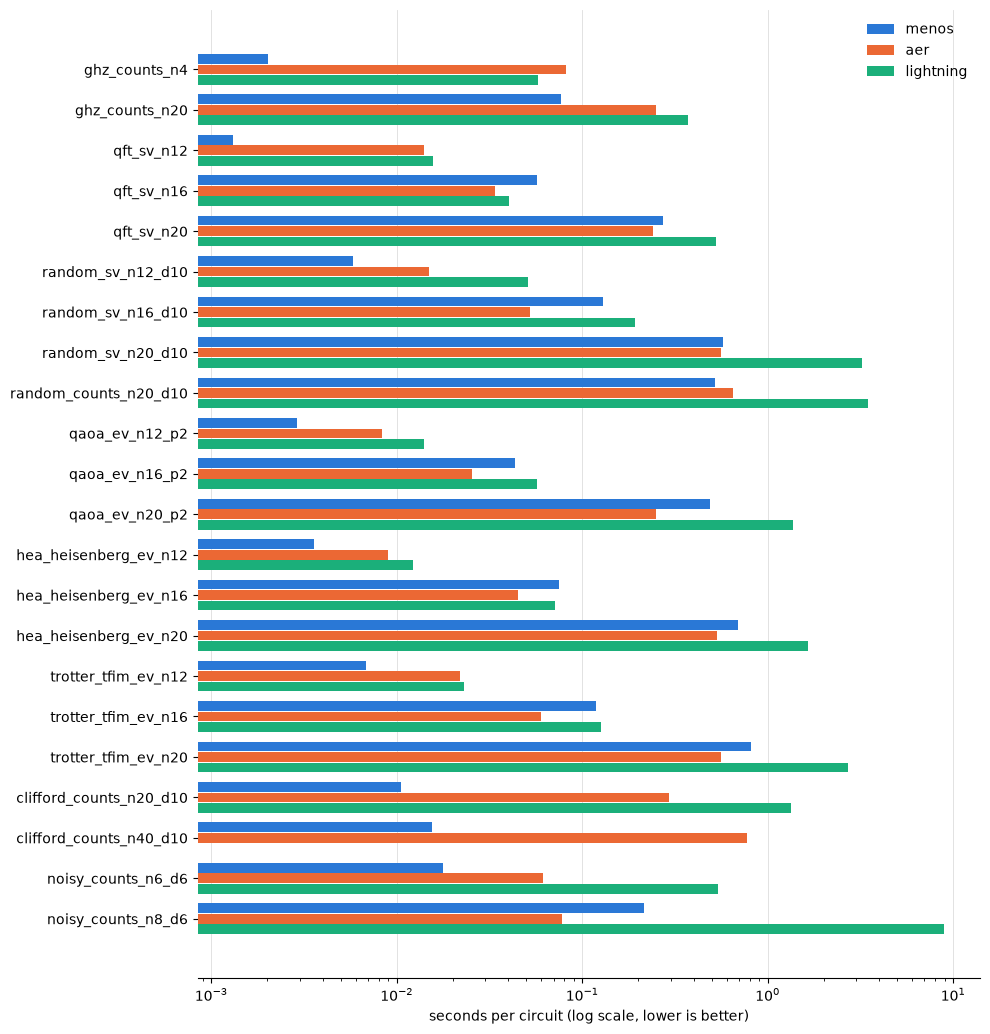

In [ ]:
import matplotlib.pyplot as plt

SERIES = {"menos": "#2a78d6", "aer": "#eb6834", "lightning": "#1baf7a"}
cases = list(df.index)
y = np.arange(len(cases))
height = 0.26

fig, ax = plt.subplots(figsize=(10, 0.42 * len(cases) + 1.2))
for k, (sim, color) in enumerate(SERIES.items()):
    values = df[sim].to_numpy(dtype=float)
    ax.barh(y + (k - 1) * height, np.nan_to_num(values, nan=0.0), height=height * 0.92, color=color, label=sim)
ax.set_yticks(y, cases)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("seconds per circuit (log scale, lower is better)")
ax.grid(axis="x", color="#dddddd", linewidth=0.6)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

### What the planner chose

MENOS does not run every circuit on a dense statevector. `explain()` shows the
candidate plans it priced and why it picked one. Two examples: the 20-qubit GHZ
circuit, which the planner sent to the matrix-product-state engine, and the
40-qubit Clifford circuit, which went to the stabilizer engine.

In [ ]:
for case in (ghz(20), random_clifford(40, 10)):
    circuit, options = menos_job(case)
    print(f"==== {case.name} ====")
    print(menos.run(circuit, options).explain())
    print()

==== ghz_counts_n20 ====
MENOS EXECUTION REPORT
circuit    qubits=20 clbits=20 operations=40 depth=21 global_phase=0
light_cone qubits 20->20 operations 40->40
candidate 0strategy=direct_dense feasible=true winner=false peak_bytes=19260776 work_units=83886080
candidate 1strategy=direct_stabilizer feasible=true winner=false peak_bytes=2413512 work_units=1240
candidate 2strategy=direct_mps feasible=true winner=true peak_bytes=2409176 work_units=340
strategy   direct_mps (exact)
region 0   qubits=[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19] engine=mps backend=cpu
estimated  state_bytes=2409176 work_units=340
actual     state_bytes=2409176 execute_s=0.000480 sample_s=0.081281 plan_s=0.000089 peak_host_bytes=6240 peak_device_bytes=0

==== clifford_counts_n40_d10 ====
MENOS EXECUTION REPORT
circuit    qubits=40 clbits=40 operations=640 depth=21 global_phase=0
light_cone qubits 40->40 operations 640->640
candidate 0strategy=direct_dense feasible=false winner=false reason="direct dense 

## 6. Reading the results

* **Agreement.** Every statevector matches to a fidelity of 1 within floating-point
  rounding, every expectation value matches at the 1e-12 level, and the GHZ, noisy and
  dense sampled distributions agree within sampling noise. The exception is the Clifford
  counts, where MENOS's stabilizer sampler is wrong on some qubits (section 5 above).
  Note also that MENOS's dense sampler and Aer differ in no marginal at all under the same
  seed on the dense and noisy counts cases: the two draw the same sample.
* **Dense circuits** (QFT, random layers, QAOA, the hardware-efficient ansatz, Trotter) go to
  a statevector in every simulator. There the comparison is one kernel implementation
  against another: MENOS and Aer trade places within about 2× of each other, with Aer ahead
  at 16 qubits and MENOS ahead at 12, and Lightning is 1–6× slower at 20 qubits.
* **Structured circuits** are where MENOS differs: the 20-qubit GHZ circuit goes to its
  matrix-product-state engine (the 4-qubit one to the stabilizer engine) and the Clifford circuits to its stabilizer engine, so the
  cost stops growing as $2^n$ (the 40-qubit Clifford circuit runs in about 15 ms and under
  1 MiB). Aer's `automatic` method also detects Clifford circuits, at 20–50× the time here,
  and switches to MPS only on request. Lightning is always a statevector.
* **Noise.** The exact density matrix is the only option in MENOS and Aer here; PennyLane's
  `default.mixed` is 40× slower at 8 qubits.
* **Planning cost.** `menos_plan_s` is paid on every `menos.run`; it is under a millisecond
  for every circuit here, so it matters only for the sub-millisecond cases.
* **Caveats.** Single machine, single run of the notebook, best-of-`REPEATS`, every
  simulator on every hardware thread; the figures are for one circuit at a time, not a
  batch.